<a href="https://colab.research.google.com/github/kimve1969/msu_ds_pinn_2d_heat/blob/main/plot_alpha_heat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Картинки для визуализации вариантом дискретной теплопроводности

Картинки нужны для аттестационной работы и наглядности расчета коэффициента эффективной теплопроводности, а именно как:

$$ k_{eff} = \frac{2 k_L k_R}{k_L + k_R}  $$

код python для формирования картинок сгенерирован в Deepseek

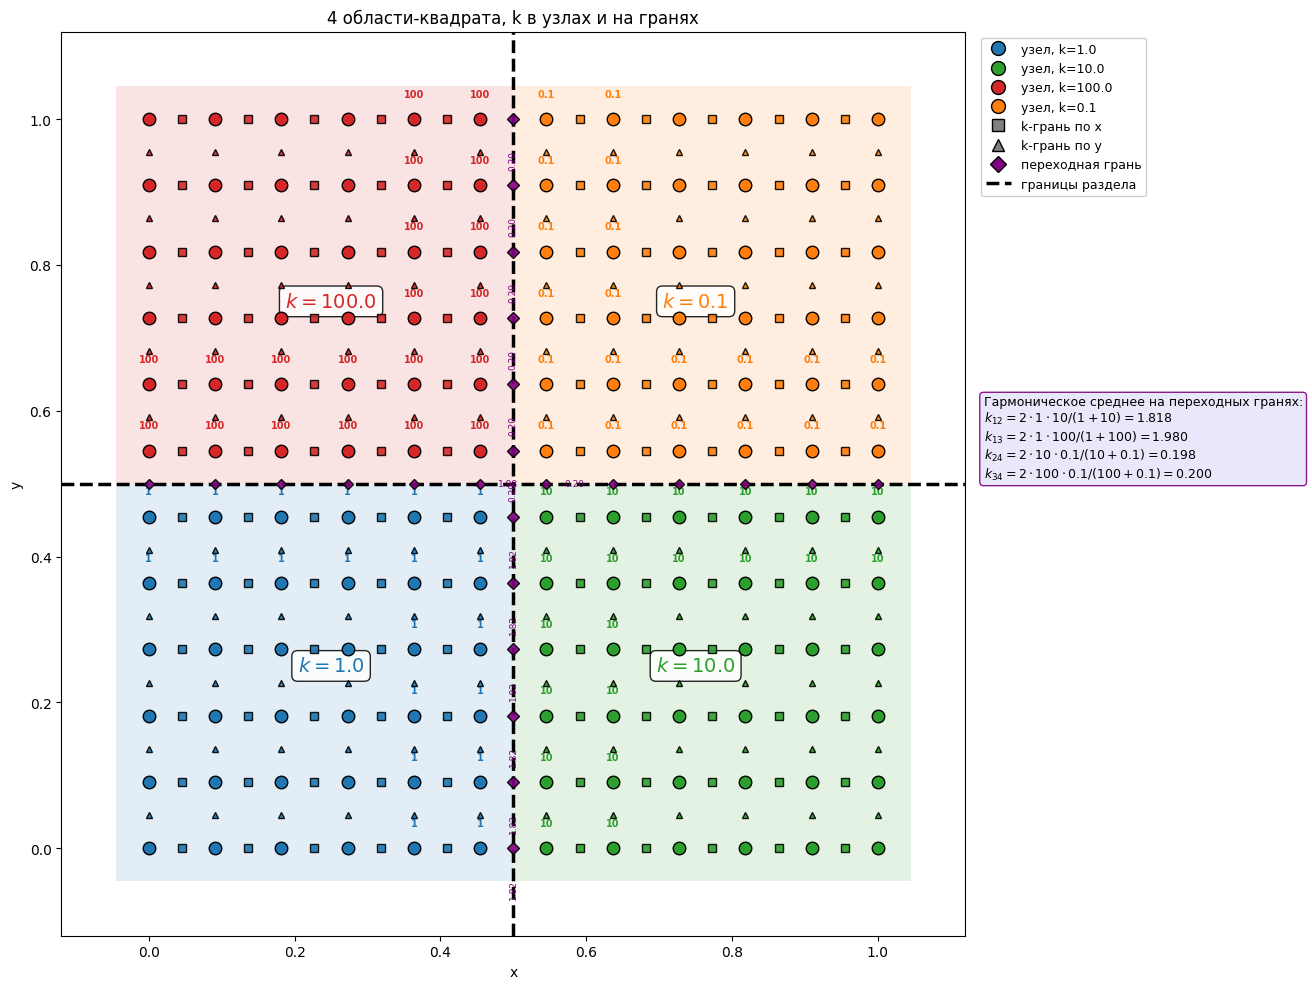

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

# ============================================================
# 1. Сетка (для наглядности небольшая; для расчёта поставьте 100)
# ============================================================
Nx, Ny = 12, 12            # узлов по x и y (для картинки)
Lx, Ly = 1.0, 1.0
hx, hy = Lx/(Nx-1), Ly/(Ny-1)

x = np.linspace(0, Lx, Nx)
y = np.linspace(0, Ly, Ny)
X, Y = np.meshgrid(x, y, indexing='ij')

# ============================================================
# 2. Четыре области-квадрата 2x2 со своими k
#    (границы раздела: x=0.5 и y=0.5)
# ============================================================
k1, k2, k3, k4 = 1.0, 10.0, 100.0, 0.1   # разные материалы

k = np.zeros((Nx, Ny))
k[(X <  0.5) & (Y <  0.5)] = k1   # левый-нижний
k[(X >= 0.5) & (Y <  0.5)] = k2   # правый-нижний
k[(X <  0.5) & (Y >= 0.5)] = k3   # левый-верхний
k[(X >= 0.5) & (Y >= 0.5)] = k4   # правый-верхний

# ============================================================
# 3. Эффективная k на гранях — гармоническое среднее
# ============================================================
kx_face = 2*k[:-1,:]*k[1:,:]/(k[:-1,:]+k[1:,:])   # (Nx-1, Ny)
ky_face = 2*k[:,:-1]*k[:,1:]/(k[:,:-1]+k[:,1:])   # (Nx, Ny-1)

# ============================================================
# 4. Рисуем
# ============================================================
fig, ax = plt.subplots(figsize=(12, 10))
ax.set_aspect('equal')
ax.set_xlim(-0.12, Lx+0.12)
ax.set_ylim(-0.12, Ly+0.12)
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('4 области-квадрата, k в узлах и на гранях')

# --- Палитра по областям ---
region_color = {k1:'tab:blue', k2:'tab:green', k3:'tab:red', k4:'tab:orange'}
k_to_color = {k1:'tab:blue', k2:'tab:green', k3:'tab:red', k4:'tab:orange'}

def face_color(val):
    """Цвет грани: если совпадает с материалом — его цвет, иначе — фиолетовый (переход)."""
    for kk, cc in k_to_color.items():
        if abs(val - kk) < 1e-9:
            return cc
    return 'purple'

# 4a) Ячейки (полупрозрачные)
for i in range(Nx):
    for j in range(Ny):
        ax.add_patch(Rectangle((x[i]-hx/2, y[j]-hy/2), hx, hy,
                               facecolor=k_to_color[k[i,j]], alpha=0.13,
                               edgecolor='none'))

# 4b) Границы раздела областей
ax.axvline(0.5, color='k', lw=2.5, ls='--')
ax.axhline(0.5, color='k', lw=2.5, ls='--')

# 4c) Подписи областей (в углах)
ax.text(0.25, 0.25, f'$k={k1}$', ha='center', va='center',
        fontsize=14, color=k_to_color[k1], fontweight='bold',
        bbox=dict(boxstyle='round', fc='white', alpha=0.85))
ax.text(0.75, 0.25, f'$k={k2}$', ha='center', va='center',
        fontsize=14, color=k_to_color[k2], fontweight='bold',
        bbox=dict(boxstyle='round', fc='white', alpha=0.85))
ax.text(0.25, 0.75, f'$k={k3}$', ha='center', va='center',
        fontsize=14, color=k_to_color[k3], fontweight='bold',
        bbox=dict(boxstyle='round', fc='white', alpha=0.85))
ax.text(0.75, 0.75, f'$k={k4}$', ha='center', va='center',
        fontsize=14, color=k_to_color[k4], fontweight='bold',
        bbox=dict(boxstyle='round', fc='white', alpha=0.85))

# 4d) Узлы с k в центрах ячеек (только подписи вблизи границы, чтобы не было каши)
show_label_band = 0.15   # полоса вокруг границ раздела
for i in range(Nx):
    for j in range(Ny):
        c = k_to_color[k[i,j]]
        ax.plot(x[i], y[j], 'o', ms=9, mfc=c, mec='k', zorder=5)
        near_v = abs(x[i]-0.5) < show_label_band
        near_h = abs(y[j]-0.5) < show_label_band
        if near_v or near_h:
            ax.text(x[i], y[j]+0.028, f'{k[i,j]:g}', ha='center', va='bottom',
                    fontsize=7, color=c, fontweight='bold', zorder=6)

# 4e) k на гранях по x (квадраты)
for i in range(Nx-1):
    for j in range(Ny):
        val = kx_face[i,j]
        xf, yf = (x[i]+x[i+1])/2, y[j]
        col = face_color(val)
        marker = 's' if col != 'purple' else 'D'
        ax.plot(xf, yf, marker, ms=6, mfc=col, mec='k', zorder=7, alpha=0.9)
        # подписи переходных граней — только в центральной полосе
        if col == 'purple' and (abs(xf-0.5) < 0.06 or abs(yf-0.5) < 0.06):
            if abs(xf-0.5) < 0.06:
                ax.text(xf, yf-0.042, f'{val:.2f}', ha='center', va='top',
                        fontsize=6.5, color='purple', zorder=8, rotation=90)

# 4f) k на гранях по y (треугольники)
for i in range(Nx):
    for j in range(Ny-1):
        val = ky_face[i,j]
        xf, yf = x[i], (y[j]+y[j+1])/2
        col = face_color(val)
        marker = '^' if col != 'purple' else 'D'
        ax.plot(xf, yf, marker, ms=5, mfc=col, mec='k', zorder=7, alpha=0.9)
        if col == 'purple' and abs(yf-0.5) < 0.06 and abs(xf-0.5) < 0.06:
            ax.text(xf+0.025, yf, f'{val:.2f}', ha='left', va='center',
                    fontsize=6.5, color='purple', zorder=8)

# ============================================================
# 5. Легенда
# ============================================================
legend_elems = [
    Line2D([0],[0], marker='o', color='w', mfc='tab:blue',   mec='k', ms=10, label=f'узел, k={k1}'),
    Line2D([0],[0], marker='o', color='w', mfc='tab:green',  mec='k', ms=10, label=f'узел, k={k2}'),
    Line2D([0],[0], marker='o', color='w', mfc='tab:red',    mec='k', ms=10, label=f'узел, k={k3}'),
    Line2D([0],[0], marker='o', color='w', mfc='tab:orange', mec='k', ms=10, label=f'узел, k={k4}'),
    Line2D([0],[0], marker='s', color='w', mfc='grey', mec='k', ms=8, label='k-грань по x'),
    Line2D([0],[0], marker='^', color='w', mfc='grey', mec='k', ms=8, label='k-грань по y'),
    Line2D([0],[0], marker='D', color='w', mfc='purple', mec='k', ms=8, label='переходная грань'),
    Line2D([0],[0], color='k', ls='--', lw=2.5, label='границы раздела'),
]
ax.legend(handles=legend_elems, loc='upper left',
          bbox_to_anchor=(1.01, 1.0), fontsize=9, framealpha=0.95)

# ============================================================
# 6. Пояснение: как считается k_face на переходных гранях
# ============================================================
def hmean(a, b): return 2*a*b/(a+b)

info = (
    "Гармоническое среднее на переходных гранях:\n"
    f"$k_{{12}} = 2\\cdot{k1:g}\\cdot{k2:g}/({k1:g}+{k2:g}) = {hmean(k1,k2):.3f}$\n"
    f"$k_{{13}} = 2\\cdot{k1:g}\\cdot{k3:g}/({k1:g}+{k3:g}) = {hmean(k1,k3):.3f}$\n"
    f"$k_{{24}} = 2\\cdot{k2:g}\\cdot{k4:g}/({k2:g}+{k4:g}) = {hmean(k2,k4):.3f}$\n"
    f"$k_{{34}} = 2\\cdot{k3:g}\\cdot{k4:g}/({k3:g}+{k4:g}) = {hmean(k3,k4):.3f}$"
)
ax.text(1.02, 0.55, info, transform=ax.transAxes, fontsize=9,
        va='center', ha='left',
        bbox=dict(boxstyle='round', fc='lavender', ec='purple', alpha=0.9))

plt.tight_layout()
plt.show()

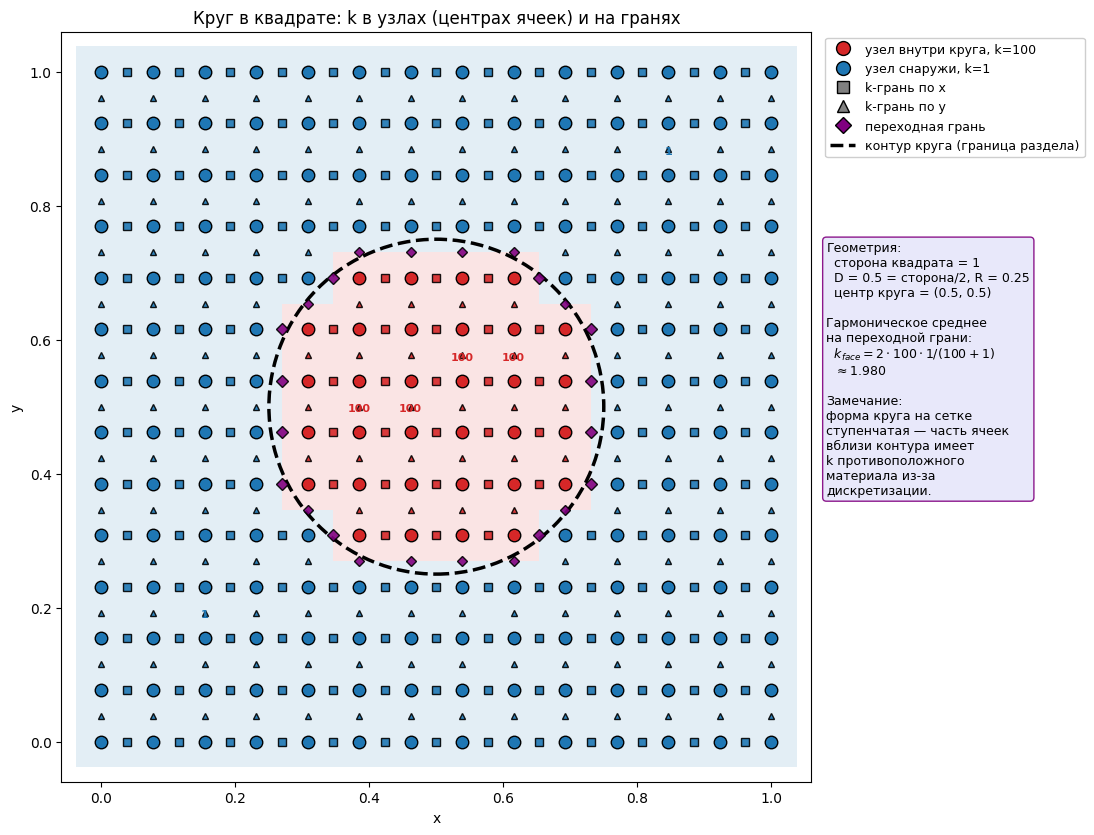

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from matplotlib.lines import Line2D

# ============================================================
# 1. Сетка
# ============================================================
Nx, Ny = 14, 14           # для картинки; для расчёта — 100
Lx, Ly = 1.0, 1.0
hx, hy = Lx/(Nx-1), Ly/(Ny-1)

x = np.linspace(0, Lx, Nx)
y = np.linspace(0, Ly, Ny)
X, Y = np.meshgrid(x, y, indexing='ij')

# ============================================================
# 2. Геометрия: круг в центре, D = 0.5 (в 2 раза меньше стороны)
# ============================================================
cx, cy = 0.5, 0.5
D = 0.5
R = D / 2.0               # R = 0.25
R2 = R**2

k_in, k_out = 100.0, 1.0  # материалы

# Маска: узел внутри круга?
inside = (X - cx)**2 + (Y - cy)**2 <= R2

k = np.where(inside, k_in, k_out)

# ============================================================
# 3. Эффективная k на гранях — гармоническое среднее
# ============================================================
kx_face = 2*k[:-1,:]*k[1:,:]/(k[:-1,:]+k[1:,:])   # (Nx-1, Ny)
ky_face = 2*k[:,:-1]*k[:,1:]/(k[:,:-1]+k[:,1:])   # (Nx, Ny-1)

# ============================================================
# 4. Рисунок
# ============================================================
fig, ax = plt.subplots(figsize=(11, 11))
ax.set_aspect('equal')
ax.set_xlim(-0.06, Lx+0.06)
ax.set_ylim(-0.06, Ly+0.06)
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('Круг в квадрате: k в узлах (центрах ячеек) и на гранях')

color_in, color_out = 'tab:red', 'tab:blue'
def col_of(v):
    return color_in if abs(v-k_in) < 1e-9 else color_out
def face_col(v):
    if abs(v-k_in)  < 1e-9: return color_in
    if abs(v-k_out) < 1e-9: return color_out
    return 'purple'

# 4a) Заливка ячеек по материалу
for i in range(Nx):
    for j in range(Ny):
        ax.add_patch(Rectangle((x[i]-hx/2, y[j]-hy/2), hx, hy,
                               facecolor=col_of(k[i,j]), alpha=0.12,
                               edgecolor='none'))

# 4b) Контур круга (истинная граница раздела)
ax.add_patch(Circle((cx, cy), R, fill=False, ec='k', lw=2.5, ls='--'))

# 4c) Узлы
for i in range(Nx):
    for j in range(Ny):
        ax.plot(x[i], y[j], 'o', ms=9, mfc=col_of(k[i,j]),
                mec='k', zorder=5)

# 4d) Грани по x (квадраты): цвет по материалу или фиолетовый
for i in range(Nx-1):
    for j in range(Ny):
        val = kx_face[i,j]
        xf, yf = (x[i]+x[i+1])/2, y[j]
        c = face_col(val)
        mk = 's' if c != 'purple' else 'D'
        ax.plot(xf, yf, mk, ms=6, mfc=c, mec='k', zorder=7, alpha=0.9)

# 4e) Грани по y (треугольники)
for i in range(Nx):
    for j in range(Ny-1):
        val = ky_face[i,j]
        xf, yf = x[i], (y[j]+y[j+1])/2
        c = face_col(val)
        mk = '^' if c != 'purple' else 'D'
        ax.plot(xf, yf, mk, ms=5, mfc=c, mec='k', zorder=7, alpha=0.9)

# 4f) Подписи k у нескольких узлов внутри и снаружи (для наглядности)
lab_pts = [(6,6), (7,7), (5,6), (8,7), (2,2), (11,11)]
for (i,j) in lab_pts:
    ax.text(x[i], y[j]+0.028, f'{k[i,j]:g}', ha='center', va='bottom',
            fontsize=8, color=col_of(k[i,j]), fontweight='bold', zorder=8)

# 4g) Подписи k_face на нескольких переходных гранях
face_lab = [
    ('x', 5, 6),   # грань по x между (5,6) и (6,6)
    ('x', 8, 7),
    ('y', 6, 5),
    ('y', 7, 8),
]
for kind, i, j in face_lab:
    if kind == 'x':
        val = kx_face[i, j]
        xf, yf = (x[i]+x[i+1])/2, y[j]
    else:
        val = ky_face[i, j]
        xf, yf = x[i], (y[j]+y[j+1])/2
    if face_col(val) == 'purple':
        ax.text(xf, yf-0.035, f'{val:.2f}', ha='center', va='top',
                fontsize=7, color='purple', zorder=9,
                bbox=dict(boxstyle='round,pad=0.1', fc='white', ec='none', alpha=0.8))

# ============================================================
# 5. Легенда и справка
# ============================================================
legend_elems = [
    Line2D([0],[0], marker='o', color='w', mfc=color_in,  mec='k', ms=10, label=f'узел внутри круга, k={k_in:g}'),
    Line2D([0],[0], marker='o', color='w', mfc=color_out, mec='k', ms=10, label=f'узел снаружи, k={k_out:g}'),
    Line2D([0],[0], marker='s', color='w', mfc='grey', mec='k', ms=8, label='k-грань по x'),
    Line2D([0],[0], marker='^', color='w', mfc='grey', mec='k', ms=8, label='k-грань по y'),
    Line2D([0],[0], marker='D', color='w', mfc='purple', mec='k', ms=8, label='переходная грань'),
    Line2D([0],[0], color='k', ls='--', lw=2.5, label='контур круга (граница раздела)'),
]
ax.legend(handles=legend_elems, loc='upper left',
          bbox_to_anchor=(1.01, 1.0), fontsize=9, framealpha=0.95)

kf = 2*k_in*k_out/(k_in+k_out)
info = (
    "Геометрия:\n"
    f"  сторона квадрата = 1\n"
    f"  D = 0.5 = сторона/2, R = 0.25\n"
    f"  центр круга = (0.5, 0.5)\n\n"
    "Гармоническое среднее\nна переходной грани:\n"
    f"  $k_{{face}} = 2\\cdot{k_in:g}\\cdot{k_out:g}/({k_in:g}+{k_out:g})$\n"
    f"  $\\approx {kf:.3f}$\n\n"
    "Замечание:\n"
    "форма круга на сетке\nступенчатая — часть ячеек\nвблизи контура имеет\nk противоположного\nматериала из-за\nдискретизации."
)
ax.text(1.02, 0.55, info, transform=ax.transAxes, fontsize=9,
        va='center', ha='left',
        bbox=dict(boxstyle='round', fc='lavender', ec='purple', alpha=0.9))

plt.tight_layout()
plt.show()